<a href="https://colab.research.google.com/github/Birravoooo20/Concrete-Compressive-Strength-Prediction/blob/main/01_Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PART A**

# **Task A1 — Import Library dan Dataset**

Di Google Colab, buat Code Cell pertama.

In [1]:

# ==========================================
# PROJECT 01: CONCRETE STRENGTH PREDICTION
# PART A: DATA EXPLORATION
# ==========================================

!pip install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Download dataset from UCI Repository

concrete = fetch_ucirepo(id=165)

# Separate input and target
X = concrete.data.features
y = concrete.data.targets

# Combine into DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset successfully loaded!")

Dataset successfully loaded!


# **Task A2 — Memahami Struktur Dataset**

In [3]:

# Dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first 10 observations
display(df.head(10))

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)


Number of rows: 1030
Number of columns: 9


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29



Column names:
['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Concrete compressive strength']

Data types:
Cement                           float64
Blast Furnace Slag               float64
Fly Ash                          float64
Water                            float64
Superplasticizer                 float64
Coarse Aggregate                 float64
Fine Aggregate                   float64
Age                                int64
Concrete compressive strength    float64
dtype: object


Pertanyaan untukmu:
1. Mengapa jumlah barisnya 1.030?
2. Apa perbedaan df.shape[0] dan df.shape[1]?
3. Mengapa kita menggunakan df.head(10)?

# **Task A3 — Statistical Analysis**

Sekarang kita ingin mengetahui karakteristik setiap variabel.

In [4]:

# Descriptive statistics

display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated Rows:")
print(df.duplicated().sum())


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000



Missing Values:
Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64

Duplicated Rows:
25


Perhatikan hasilnya.

Kamu harus menemukan:
- Mean.
- Standard deviation.
- Minimum.
- Maximum.
- Jumlah missing values.
- Jumlah duplicated rows.
Jangan langsung menghapus data yang terduplikasi. Kita analisis dahulu.

# **Task A4 — Visualisasi Data**

Sekarang bagian yang paling menarik.

Pertanyaan utama: apakah semakin banyak Cement menghasilkan Compressive Strength yang semakin tinggi?

Buat grafik pertama:

In [5]:

# Descriptive statistics

display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated Rows:")
print(df.duplicated().sum())


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000



Missing Values:
Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64

Duplicated Rows:
25


Grafik ini adalah Scatter Plot.

Setiap titik merepresentasikan satu observasi eksperimen.

Kemudian buat grafik kedua:

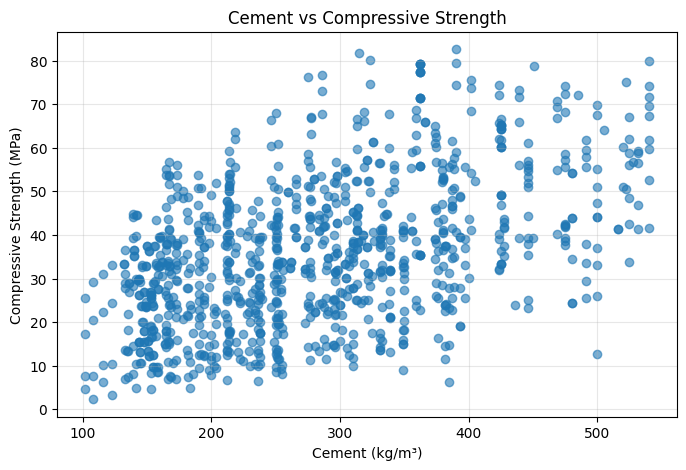

In [6]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Cement"],
    df["Concrete compressive strength"],
    alpha=0.6
)

plt.xlabel("Cement (kg/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Cement vs Compressive Strength")

plt.grid(alpha=0.3)
plt.show()


Trendline membantu kita melihat arah hubungan linear secara sederhana.

# **Task A5 — Correlation Heatmap**

Kita ingin melihat hubungan antarsemua variabel.

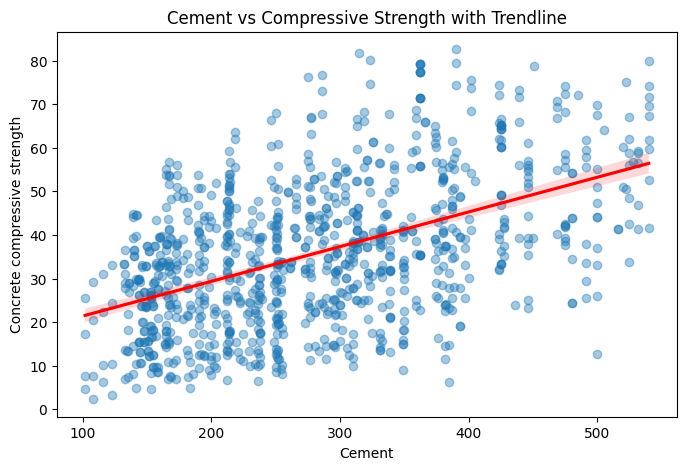

In [7]:

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="Cement",
    y="Concrete compressive strength",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Cement vs Compressive Strength with Trendline")
plt.show()


Interpretasi awal:

Correlation	Interpretasi umum

Mendekati +1	Positive linear
relationship kuat

Mendekati 0	Linear relationship lemah

Mendekati -1	Negative linear relationship kuat

Ingat: correlation bukan causation.

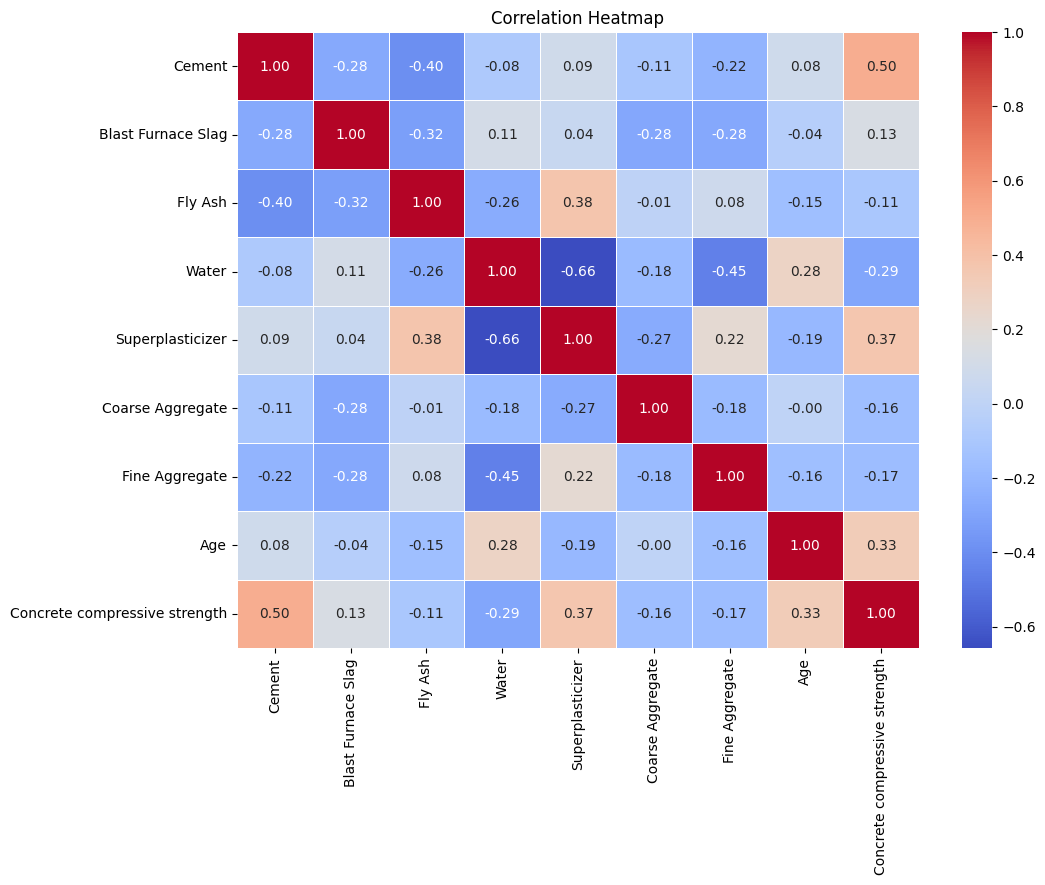

In [8]:

# Calculate correlation matrix

correlation = df.corr()

# Visualize correlation
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()


# Part B — Multiple Linear Regression

Pada Part A, kita sudah mengenali struktur dan pola awal dataset. Sekarang kita membuat model untuk memperkirakan **Concrete compressive strength (MPa)** dari delapan fitur campuran beton dan umur beton.

## Daftar isi

1. Memisahkan fitur dan target
2. Membagi data latihan dan data uji
3. Melatih model dan membaca koefisien
4. Membandingkan prediksi dengan hasil aktual
5. Mengevaluasi performa model
6. Membaca grafik aktual vs prediksi
7. Interpretasi tambahan: koefisien terstandardisasi
8. Ringkasan dan pertanyaan refleksi

### Tujuan Part B

Di akhir bagian ini, kita akan memiliki model baseline dan dapat menjelaskan cara membaca prediksi serta ukuran error-nya. Data uji disimpan untuk menilai model pada baris yang tidak dipakai saat pelatihan.

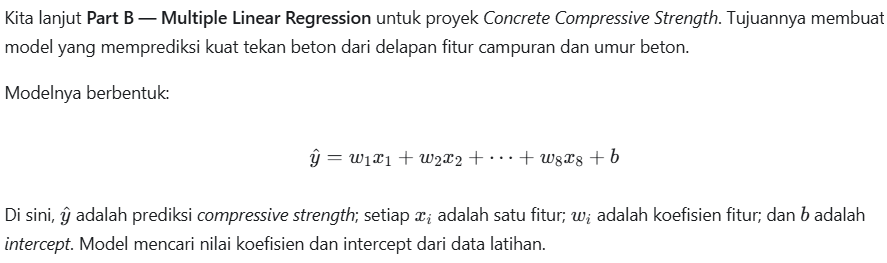

## 1. Memisahkan fitur dan target

`X` berisi delapan input yang dipakai model. `y` berisi jawaban yang ingin diprediksi, yaitu kuat tekan beton. Setiap baris di `X` harus berpasangan dengan nilai pada baris yang sama di `y`.

Kita mengharapkan `X` berukuran 1.030 × 8 dan `y` berukuran 1.030. Perintah `shape` menampilkan jumlah baris dan kolom; daftar nama fitur membantu memastikan target tidak ikut masuk ke input.

In [9]:
# X berisi 8 fitur input
X = df.drop(columns="Concrete compressive strength")

# y berisi nilai yang ingin diprediksi
y = df["Concrete compressive strength"]

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Nama fitur:", X.columns.tolist())


Ukuran X: (1030, 8)
Ukuran y: (1030,)
Nama fitur: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']


## 2. Membagi data latihan dan data uji

Kita memakai 80% data untuk melatih model dan menyisihkan 20% untuk mengujinya. Model tidak melihat data uji ketika belajar, sehingga hasil uji memberi gambaran lebih jujur tentang prediksi pada data yang belum dipakai.

`random_state=42` membuat pembagian yang sama terulang saat notebook dijalankan kembali. Dengan 1.030 baris, hasil yang diharapkan adalah 824 baris latihan dan 206 baris uji.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Ukuran X_train: (824, 8)
Ukuran X_test: (206, 8)
Ukuran y_train: (824,)
Ukuran y_test: (206,)


## 3. Melatih model dan membaca koefisien

`LinearRegression()` membuat model regresi linear berganda, lalu `fit()` menyesuaikan koefisien dari data latihan. Secara umum, modelnya berbentuk:

`prediksi = b + w₁x₁ + w₂x₂ + ... + w₈x₈`

Setiap `w` adalah koefisien satu fitur dan `b` adalah intercept. Koefisien dibaca sebagai perubahan prediksi saat fitur tersebut naik satu unit, dengan fitur lain dianggap tetap. Ini adalah hubungan yang dipelajari dari data, bukan bukti sebab-akibat. Besar koefisien mentah juga belum bisa dibandingkan langsung karena satuan dan rentang fitur berbeda.

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model selesai dilatih.")
print("Intercept (b):", model.intercept_)
print("Koefisien (w):")
for nama_fitur, koefisien in zip(X.columns, model.coef_):
    print(f"{nama_fitur}: {koefisien:.4f}")

Model selesai dilatih.
Intercept (b): -28.82355499969256
Koefisien (w):
Cement: 0.1190
Blast Furnace Slag: 0.1085
Fly Ash: 0.0822
Water: -0.1353
Superplasticizer: 0.3106
Coarse Aggregate: 0.0179
Fine Aggregate: 0.0241
Age: 0.1164


## 4. Membandingkan prediksi dengan hasil aktual

`predict()` menghasilkan prediksi untuk 206 baris uji. Tabel berikut hanya menampilkan 10 contoh pertama supaya mudah diperiksa; evaluasi keseluruhan dilakukan pada semua baris uji di langkah berikutnya.

Kolom selisih memakai rumus **aktual − prediksi**. Nilai positif berarti model memprediksi terlalu rendah; nilai negatif berarti model memprediksi terlalu tinggi. Selisih yang dekat dengan nol berarti prediksi pada baris itu dekat dengan hasil eksperimen.

In [12]:
import pandas as pd

y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "Aktual (MPa)": y_test.values[:10],
    "Prediksi (MPa)": y_pred[:10]
})

hasil["Selisih (MPa)"] = hasil["Aktual (MPa)"] - hasil["Prediksi (MPa)"]
hasil.round(2)

,Aktual (MPa),Prediksi (MPa),Selisih (MPa)
0,52.91,59.66,-6.75
1,55.90,52.04,3.86
2,74.50,63.54,10.96
3,35.30,51.58,-16.28
4,10.54,17.22,-6.68
5,44.28,39.87,4.41
6,23.69,26.70,-3.01
7,45.37,44.74,0.63
8,37.40,29.37,8.03
9,48.85,38.19,10.66


## 5. Mengevaluasi performa model

Metrik dihitung dari seluruh data uji:

- **MAE**: rata-rata besar selisih absolut, dalam MPa; mudah dibaca sebagai besar error tipikal.
- **MSE**: rata-rata kuadrat error, dalam MPa²; lebih menghukum error besar.
- **RMSE**: akar MSE, kembali dalam MPa; juga lebih sensitif terhadap error besar dibanding MAE.
- **R²**: membandingkan hasil model dengan tebakan sederhana berupa rata-rata target. Nilai yang lebih tinggi biasanya lebih baik pada data uji, tetapi bukan persentase prediksi yang benar.

Gunakan nilai-nilai ini bersama grafik dan konteks penggunaan; satu metrik saja tidak cukup untuk menyatakan model sudah baik.

Pada hasil yang kita peroleh, **MAE = 7,75 MPa** berarti besar selisih absolut prediksi rata-rata sekitar 7,75 MPa pada data uji. **RMSE = 9,80 MPa** lebih besar karena lebih memberi bobot pada error besar. **R² = 0,628** menunjukkan model menjelaskan sekitar 62,8% variasi kuat tekan pada data uji dibandingkan baseline rata-rata target; ini bukan berarti 62,8% prediksi tepat.


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f} MPa")
print(f"MSE:  {mse:.2f} MPa²")
print(f"RMSE: {rmse:.2f} MPa")
print(f"R²:   {r2:.3f}")

MAE:  7.75 MPa
MSE:  95.97 MPa²
RMSE: 9.80 MPa
R²:   0.628


## 6. Membaca grafik aktual vs prediksi

Setiap titik mewakili satu data uji. Sumbu mendatar adalah nilai aktual dan sumbu tegak adalah prediksi. Garis merah putus-putus menunjukkan prediksi sempurna (`prediksi = aktual`). Titik yang dekat dengan garis berarti prediksinya lebih dekat.

Perhatikan apakah titik menyebar jauh dari garis, dan apakah model cenderung terlalu tinggi atau terlalu rendah pada rentang tertentu. Grafik ini membantu melihat pola error yang tidak terlihat dari satu angka metrik.

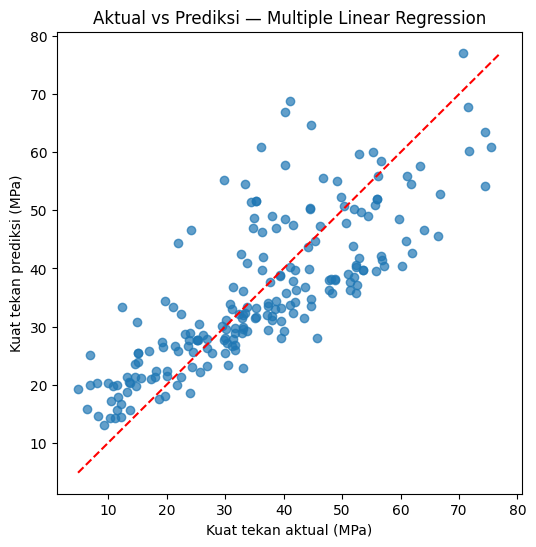

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

batas_min = min(y_test.min(), y_pred.min())
batas_maks = max(y_test.max(), y_pred.max())
plt.plot([batas_min, batas_maks], [batas_min, batas_maks], "r--")

plt.xlabel("Kuat tekan aktual (MPa)")
plt.ylabel("Kuat tekan prediksi (MPa)")
plt.title("Aktual vs Prediksi — Multiple Linear Regression")
plt.show()

## 7. Interpretasi tambahan: koefisien terstandardisasi

Fitur seperti `Age` dan `Cement` memiliki skala yang berbeda, sehingga koefisien mentah sulit dibandingkan. Di sini `StandardScaler` mengubah fitur agar rata-ratanya 0 dan simpangan bakunya 1. Scaler dipasang hanya pada data latihan melalui pipeline, lalu transformasi yang sama dipakai ketika pipeline memprediksi.

Koefisien terstandardisasi dapat dibaca sebagai perubahan prediksi (MPa) untuk kenaikan **satu simpangan baku** pada suatu fitur, dengan fitur lain dianggap tetap. Besar absolutnya membantu membandingkan hubungan linear dalam model, tetapi bukan ukuran sebab-akibat dan dapat dipengaruhi keterkaitan antarfitur. Model ini dipakai untuk interpretasi; kita belum sedang membandingkan performa model terskalakan.

Pada hasil kita, koefisien standar terbesar berdasarkan nilai absolut adalah Cement (**12,79 MPa per satu simpangan baku**), lalu Blast Furnace Slag (**9,43 MPa**) dan Age (**7,04 MPa**). Water memiliki koefisien **−2,88 MPa per satu simpangan baku**. Ini menunjukkan pola asosiasi linear yang dipelajari model setelah fitur lain diperhitungkan; jangan ditafsirkan sebagai efek kausal.


In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd

model_scaled = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model_scaled.fit(X_train, y_train)

koefisien_scaled = pd.Series(
    model_scaled.named_steps["linearregression"].coef_,
    index=X.columns
).sort_values(key=abs, ascending=False)

print("Koefisien setelah fitur distandardisasi:")
display(koefisien_scaled.to_frame("Koefisien"))

Koefisien setelah fitur distandardisasi:


,Koefisien
Cement,12.788413
Blast Furnace Slag,9.434456
Age,7.037434
Fly Ash,5.254578
Water,-2.882597
Fine Aggregate,1.950529
Superplasticizer,1.852126
Coarse Aggregate,1.405196


## 8. Ringkasan dan pertanyaan refleksi

Part B menghasilkan model baseline regresi linear berganda. Simpan hasil metrik dan grafik sebagai pembanding untuk bagian berikutnya. Model menangkap hubungan linear dari data, tetapi prediksi individual masih dapat meleset.

Sebelum lanjut, coba jawab dengan kata-katamu sendiri:

1. Mengapa kita menyisihkan data uji sebelum melatih model?
2. Apa arti MAE 7,75 MPa untuk hasil prediksi pada dataset ini?
3. Pada grafik, apa arti titik yang berada di atas garis merah? Bagaimana dengan titik di bawahnya?
4. Mengapa koefisien mentah tidak cukup untuk menentukan fitur yang “paling berpengaruh”?

### Simpan pekerjaan

Jika sudah membuka salinan notebook di Google Drive, simpan notebook. Untuk memperbarui repositori GitHub, gunakan **Save in GitHub** dan pilih repositori serta nama file yang sesuai.